In [1]:
import sys
import os
import json
import random
import matplotlib.pyplot as plt
from IPython.display import clear_output
import pandas as pd
import geopandas as gpd


sys.path.append('../')
import model.dataloader as dataloader
from model.dataset import LABEL_MAPPING


In [2]:
inverse_label_mapping = {value : key for key, value in LABEL_MAPPING.items()}

In [3]:
config = {
    

    "data": {
        "annotation_file": "/home/jan/Documents/EPFL/project_2/data/labels/dataset_v4/labels_55k.csv",
        "image_folder": "/home/jan/Documents/EPFL/project_2/data/images/dataset_v4/55k/SR_four_images",
        "forestloss_folder": "/home/jan/Documents/EPFL/project_2/data/forestloss_tiles/dataset_v4_nonbinarized",
        "tabular_production_data": "/home/jan/Documents/EPFL/project_2/data/tmp/deduce_tabular.csv",
        "output_folder":  "models_trained/"
    },
    "num_workers" : 32,

    "hyperparams" :{
        "seed": [420],
        "batch_size": [64],
        "learning_rate": [0.0005],
        "epochs": [1000],
        "weight_decay": [0.002],
        "randomize_labels": ["False"],
        "in_channels": [4],
        "use_forestloss" : ["True"],
        "early_stopping_patience": [20],

        "embedding_dim" : [128],
        

        "image_encoder": [

            {
                "use" : "True",
                "type" : "cnn",
                "backbone": "resnet18",
                "pretrained_backbone" : "True",
                "moco_weights" : "False",
                "freeze" : "False"

            }
        ],

        "loc_encoder": [

            {
                "use" : "True",
                "positional_embedding": "cartesian3d"
            }

        ],   

        "tabular_encoder": [

            {
                "use" : "True",
                "type" : "deduce_token"
            }         
        ],

        
        "classifier": [


            {
                "type" : "transformer",
                "transformer_layers": 3,
                "attention_heads":8
            }            
        ],

        "folds_to_split" : [

            {
                "column" : "split",
                "mapping"  : {
                    "0" : "train",
                    "1" : "train",
                    "2" : "train",
                    "3" : "val",
                    "4" : "test"
                }
            }


        ],

        "forestloss_params": [
            {
                "kernel_size" : 15,
                "sigma" : 6,
                "apply_after_layer" : 3
            }
        ]


    },

    "wandb": {
        "log_to_wandb" : "True",
        "project" : "project_2",
        "entity" : "janpisl",
        "group": "26/4 deduce data"
    }
}


In [4]:
import itertools

try:
    keys, values = zip(*config['hyperparams'].items())
    permutations_dicts = [dict(zip(keys, v)) for v in itertools.product(*values)]
except TypeError: #If the config options are not iterable, just run a single experiment with the config as is
    permutations_dicts = [dict(config['hyperparams'])]
print(f"{len(permutations_dicts)} variant(s) of config")

config['hyperparams'] = permutations_dicts[0]

1 variant(s) of config


In [5]:
# fetch dataloaders
dataloaders = dataloader.fetch_dataloader(
    ['train', 'val'], config)
train_dl = dataloaders['train']
val_dl = dataloaders['val']

In [6]:
x,y = next(iter(train_dl))

In [7]:
def plot_images(data, tmf, label):
    
    n_images = data.shape[0]
    print(label)
    fig, ax = plt.subplots(1,n_images+1, figsize=(16, 16))
    idx = 0
    for idx in range(n_images):
        img = data[idx, :3, :, :].detach()
        img = img/0.25

        ax[idx].imshow(img.permute(1, 2, 0)[:,:,[2,1,0]].numpy()  )
        ax[idx].set_xticks([])
        ax[idx].set_yticks([])

    ax[n_images].imshow(tmf.permute(1, 2, 0).numpy())
    ax[n_images].set_xticks([])
    ax[n_images].set_yticks([])
    
    fig.tight_layout()
    plt.show()
    



Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


geometry    POINT (-53.31572580239505 -13.174915669592865)
driver                                                 soy
sampleid                                          10589944
dataset                                      mapbiomas.csv
split                                                train
country                                             Brazil
Name: 29081, dtype: object
tensor([15.3150, -0.7029,  0.7696, -0.4717,  0.3764,  0.0000,  0.0000, -0.3827,
        -0.9009,  0.0000,  0.0000,  0.0000])
soy


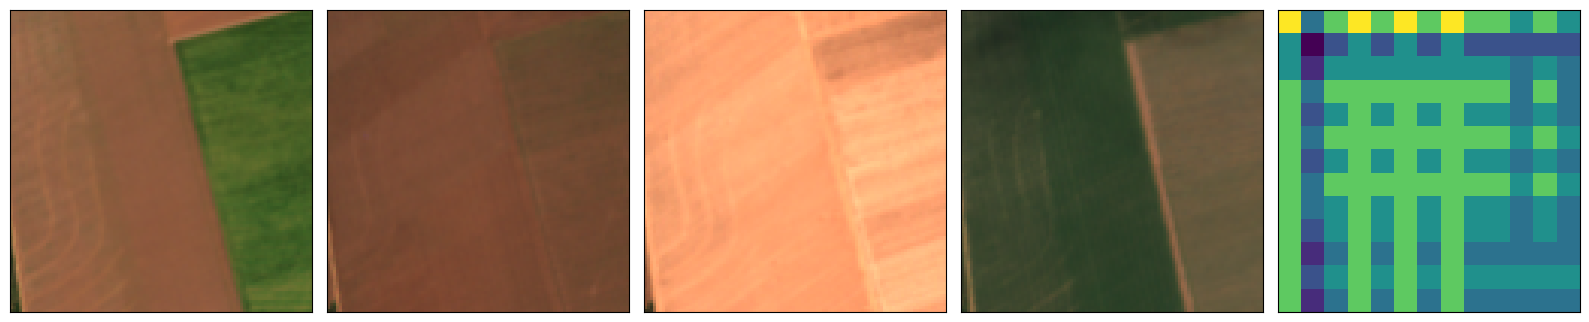

KeyboardInterrupt: Interrupted by user

In [9]:
dataset = train_dl.dataset

#for i in range(len(dataset)):
while True:
    i = random.randint(0,len(dataset.img_labels))
    #if not train_dataset.img_labels.iloc[i].driver == 'shifting agriculture':
    #    continue
    #print(dataset.img_labels.iloc[i].sampleid, dataset.img_labels.iloc[i].dataset)
    print(dataset.img_labels.iloc[i])
    input_batch, label = train_dl.dataset.__getitem__(i)
    image_data, loc, tabular_data, forestloss_data = input_batch
    print(tabular_data)
    plot_images(image_data,forestloss_data, label= inverse_label_mapping[label])

    _waitforinput = input()

    clear_output(wait=True)

    
    
    
    

In [13]:
forestloss_dir = "/home/jan/Documents/EPFL/project_2/data/forestloss_tiles/dataset_v4_nonbinarized"
import rasterio

In [17]:
sampleid

'10589944'

In [14]:
sampleid = str(dataset.img_labels.iloc[i]['sampleid'])
path = os.path.join(forestloss_dir, f'{sampleid}.tif')
with rasterio.open(path) as source:
    _tmf = source.read()

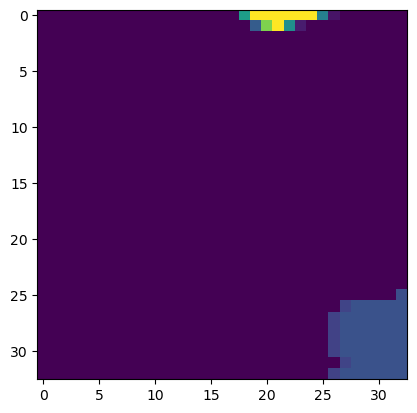

In [16]:
plt.imshow(_tmf.squeeze())

In [24]:
from torchvision import transforms
from model.dataloader import BinarizeTensor


In [20]:
torch.Tensor(_tmf)

tensor([[[2003., 2003., 2003.,  ..., 2003., 2003., 2003.],
         [2003., 2003., 2003.,  ..., 2003., 2003., 2003.],
         [2003., 2003., 2003.,  ..., 2003., 2003., 2003.],
         ...,
         [2003., 2003., 2003.,  ..., 2004., 2004., 2004.],
         [2003., 2003., 2003.,  ..., 2004., 2004., 2004.],
         [2003., 2003., 2003.,  ..., 2004., 2004., 2004.]]])

In [27]:
kernel_size = (config['hyperparams']['forestloss_params']['kernel_size'], config['hyperparams']['forestloss_params']['kernel_size'])
binarize = BinarizeTensor()
blur = transforms.GaussianBlur(
                    kernel_size, 
                    sigma=config['hyperparams']['forestloss_params']['sigma'],
                    )

tensor([[[0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         ...,
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.]]])

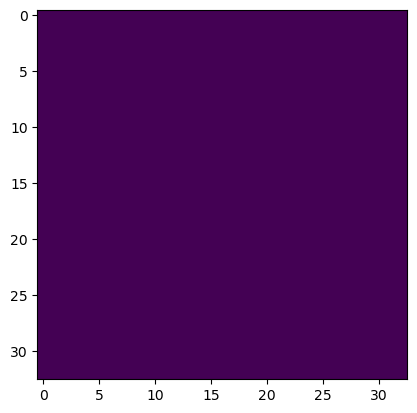

In [39]:
plt.imshow(binarize(torch.Tensor(_tmf)).squeeze().numpy())

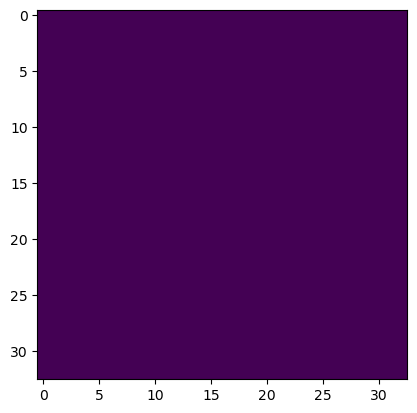

In [40]:
plt.imshow(blur(binarize(torch.Tensor(_tmf))).squeeze().numpy())

In [43]:
blur(binarize(torch.Tensor(_tmf)))

tensor(0.)

In [27]:
forestloss_dir = "/home/jan/Documents/EPFL/project_2/data/forestloss_tiles/dataset_v4"

In [28]:
with rasterio.open(os.path.join(forestloss_dir, f"{str(10577609)}.tif")) as src:
    tile = src.read()

In [30]:
tile.min()

1.0

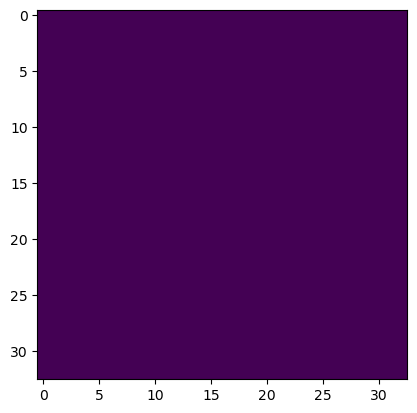

In [32]:
plt.imshow(tile.squeeze())

In [ ]:
sampleids = [
2040330, #forest plant. looks like palm oil
    5000927, #forest plant. looks like palm oil
    8118421,  #forest plant. looks like palm oil
]

In [21]:
train_dataset.img_labels.loc[train_dataset.img_labels.sampleid == 5002879]

,geometry,driver,sampleid,split
7438,POINT (105.97349049958846 14.335897554805385),shifting agriculture,5002879,train
